# Fatores Institucionais e Risco de Abandono Escolar no Ensino Medio
## Grupo: Brazilian Education Data | PUC Minas — Ciencia de Dados

---

## Objetivo

Este notebook analisa quais **caracteristicas institucionais das escolas publicas**
estao associadas ao risco de abandono escolar no Ensino Medio, usando os microdados
do Censo Escolar 2025 e as taxas oficiais de rendimento do INEP 2024.

O trabalho tem dois objetivos complementares:

1. **Descritivo**: identificar e explicar quais fatores institucionais estao
   associados ao abandono — *o que caracteriza uma escola de alto risco?*
2. **Preditivo**: construir um sistema de alerta que classifica cada escola
   em nivel de risco — *esta escola e susceptivel ao abandono?*

---

## Fontes de dados

| Base | Ano | Papel |
|---|---|---|
| Tabela_Escola_2025.csv | 2025 | Atributos institucionais (features) |
| Tabela_Matricula_2025.csv | 2025 | Matriculas no Ensino Medio regular |
| tx_rend_escolas_2024.xlsx | 2024 | **Variavel-alvo**: taxa oficial de abandono |

> **Limitacao temporal reconhecida:** a variavel-alvo e de 2024 e os atributos
> institucionais sao de 2025. A analise e exploratoria e associativa, nao causal.

---

## Estrutura do Notebook

1. Importacoes
2. Carregamento e integracao das bases
3. Analise exploratoria da variavel-alvo
4. Feature engineering
5. Pre-processamento
6. **Modelo 1 — Arvore de Decisao** (descritivo e interpretativo)
7. **Modelo 2 — Random Forest** (preditivo — sistema de alerta)
8. Sistema de alerta em cascata (3 niveis)
9. Comparacao e conclusoes


## 1. Importacoes

Todas as bibliotecas necessarias para o projeto.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    accuracy_score, f1_score
)

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 120})
sns.set_theme(style='whitegrid', palette='muted')
SEED = 42
print('Bibliotecas carregadas com sucesso.')


Bibliotecas carregadas com sucesso.


## 2. Carregamento e Integracao das Bases

### 2.1 Leitura dos arquivos

Tres bases sao integradas pela chave `CO_ENTIDADE` (codigo unico de cada escola).
O escopo e restrito a escolas que ofertam **Ensino Medio regular tradicional**
(`IN_COMUM_MEDIO_MEDIO == 1`) com pelo menos uma matricula no EM diurno ou noturno.


In [2]:
# Caminhos dos arquivos — ajuste conforme necessario
CAMINHO_ESCOLA    = 'Tabela_Escola_2025.csv'
CAMINHO_MATRICULA = 'Tabela_Matricula_2025.csv'
CAMINHO_REND      = 'tx_rend_escolas_2024.xlsx'

# Leitura da base de escolas
escola_df = pd.read_csv(CAMINHO_ESCOLA, sep=';', encoding='latin1', low_memory=False)

# Leitura da base de matriculas
matricula_df = pd.read_csv(CAMINHO_MATRICULA, sep=';', encoding='latin1', low_memory=False)

# Leitura das taxas de rendimento 2024
# O arquivo tem 8 linhas de cabecalho antes dos dados reais
rend_df = pd.read_excel(CAMINHO_REND, skiprows=8)
rend_df['TX_ABANDONO_MED'] = pd.to_numeric(rend_df['3_CAT_MED'], errors='coerce')

print(f'Escola:     {escola_df.shape}')
print(f'Matricula:  {matricula_df.shape}')
print(f'Rendimento: {rend_df.shape} | Com dado EM: {rend_df["TX_ABANDONO_MED"].notna().sum():,}')


Escola:     (214192, 302)
Matricula:  (178766, 237)
Rendimento: (128098, 64) | Com dado EM: 29,727


### 2.2 Integracao e filtragem

In [3]:
# Padronizar chave de integracao para Int64 em todas as bases
for df in [escola_df, matricula_df, rend_df]:
    df['CO_ENTIDADE'] = pd.to_numeric(df['CO_ENTIDADE'], errors='coerce').astype('Int64')

# Filtrar apenas escolas com Ensino Medio regular tradicional
escola_medio = escola_df[escola_df['IN_COMUM_MEDIO_MEDIO'] == 1].copy()
print(f'Escolas c/ EM regular: {len(escola_medio):,} ({len(escola_medio)/len(escola_df)*100:.1f}% do total)')

# Filtrar matriculas: ao menos 1 aluno no EM diurno ou noturno
for c in ['QT_MAT_MED_D', 'QT_MAT_MED_N']:
    matricula_df[c] = pd.to_numeric(matricula_df[c], errors='coerce').fillna(0)

mat_medio = matricula_df[
    (matricula_df['QT_MAT_MED_D'] > 0) | (matricula_df['QT_MAT_MED_N'] > 0)
][['CO_ENTIDADE','QT_MAT_MED_D','QT_MAT_MED_N']].copy()

# Integrar escola + matricula (inner join)
base = escola_medio.merge(mat_medio, on='CO_ENTIDADE', how='inner')

# Integrar com taxa de abandono 2024
rend_medio = rend_df[rend_df['TX_ABANDONO_MED'].notna()][['CO_ENTIDADE','TX_ABANDONO_MED']].copy()
base_final = base.merge(rend_medio, on='CO_ENTIDADE', how='inner')

# Mapear dependencia administrativa
base_final['TP_DEPENDENCIA'] = pd.to_numeric(base_final['TP_DEPENDENCIA'], errors='coerce')
DEP_MAP = {1:'Federal', 2:'Estadual', 3:'Municipal', 4:'Privada'}
base_final['DEP_NOME'] = base_final['TP_DEPENDENCIA'].map(DEP_MAP)

print(f'Base integrada: {len(base_final):,} escolas')


Escolas c/ EM regular: 26,822 (12.5% do total)
Base integrada: 25,704 escolas


## 3. Analise Exploratoria da Variavel-Alvo

### 3.1 Por que focamos nas escolas publicas?

Antes de modelar, e essencial entender a distribuicao do abandono por rede administrativa.
Escolas privadas tem dinamica estruturalmente distinta — a evasao ocorre principalmente
por inadimplencia, nao por vulnerabilidade institucional. Inclui-las contaminaria o modelo
com um sinal espurio.


Taxa de abandono por rede:
               n  media  mediana  pct_zero
DEP_NOME                                  
Estadual   18014   3.70      2.1      27.5
Federal       58   1.23      0.0      56.9
Municipal    107   3.14      0.8      40.2
Privada     7525   0.15      0.0      92.2


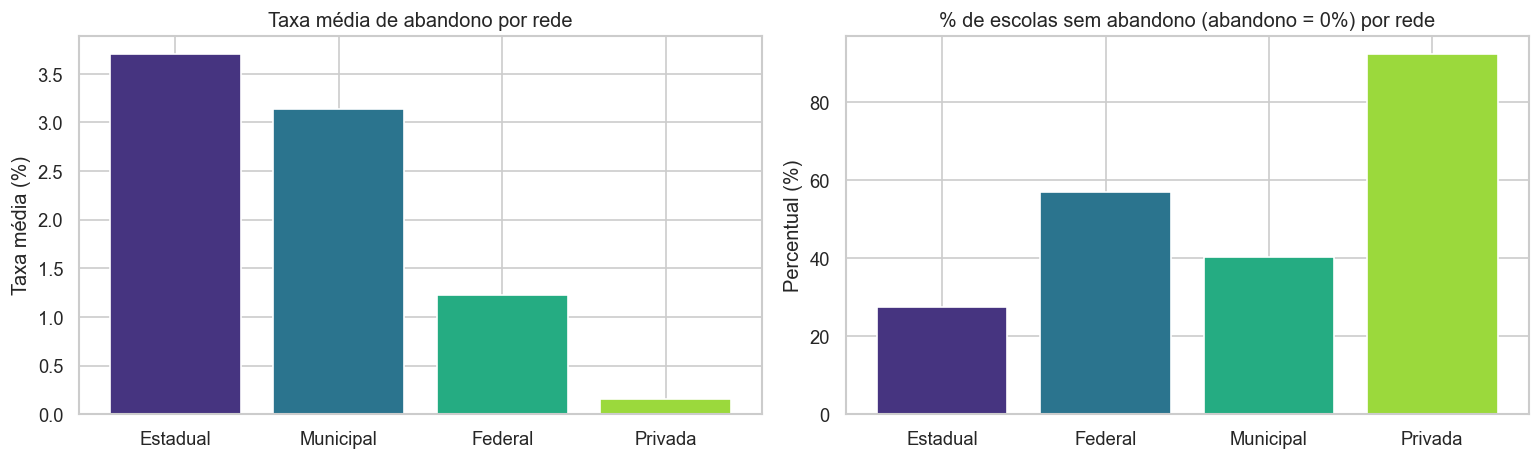

CONCLUSÃO: escolas privadas apresentam percentual muito elevado de abandono zero.
Por isso, a análise foca nas escolas públicas.


In [32]:
# Comparar abandono por rede administrativa
resumo_dep = base_final.groupby('DEP_NOME')['TX_ABANDONO_MED'].agg(
    n='count',
    media='mean',
    mediana='median',
    pct_zero=lambda x: round((x == 0).mean() * 100, 1)
).round(2)

print('Taxa de abandono por rede:')
print(resumo_dep)

# Visualização
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Paleta Viridis com 4 cores
cores_viridis = plt.cm.viridis(np.linspace(0.15, 0.85, 4))

# Taxa média por rede
dep_media = base_final.groupby('DEP_NOME')['TX_ABANDONO_MED'].mean().sort_values(ascending=False)

axes[0].bar(
    dep_media.index,
    dep_media.values,
    color=cores_viridis
)

axes[0].set_title('Taxa média de abandono por rede')
axes[0].set_ylabel('Taxa média (%)')

# Percentual de escolas sem abandono
dep_zero = base_final.groupby('DEP_NOME')['TX_ABANDONO_MED'].apply(lambda x: (x == 0).mean() * 100)

axes[1].bar(
    dep_zero.index,
    dep_zero.values,
    color=cores_viridis
)

axes[1].set_title('% de escolas sem abandono (abandono = 0%) por rede')
axes[1].set_ylabel('Percentual (%)')

plt.tight_layout()
plt.savefig('eda_abandono_por_rede_viridis.png', dpi=300, bbox_inches='tight')
plt.show()

print('CONCLUSÃO: escolas privadas apresentam percentual muito elevado de abandono zero.')
print('Por isso, a análise foca nas escolas públicas.')

### 3.2 Base publica — distribuicao do abandono

In [6]:
# Restringir a escolas publicas (federal=1, estadual=2, municipal=3)
base_pub = base_final[base_final['TP_DEPENDENCIA'].isin([1, 2, 3])].copy()

print(f'Base publica: {len(base_pub):,} escolas')
print(f'Com abandono > 0%: {(base_pub["TX_ABANDONO_MED"]>0).sum():,}')
print(f'Com abandono > 5%: {(base_pub["TX_ABANDONO_MED"]>5).sum():,}')
print()
print('Estatisticas da taxa de abandono:')
print(base_pub['TX_ABANDONO_MED'].describe().round(2))


Base publica: 18,179 escolas
Com abandono > 0%: 13,150
Com abandono > 5%: 4,881

Estatisticas da taxa de abandono:
count    18179.00
mean         3.69
std          5.09
min          0.00
25%          0.00
50%          2.10
75%          5.40
max        100.00
Name: TX_ABANDONO_MED, dtype: float64


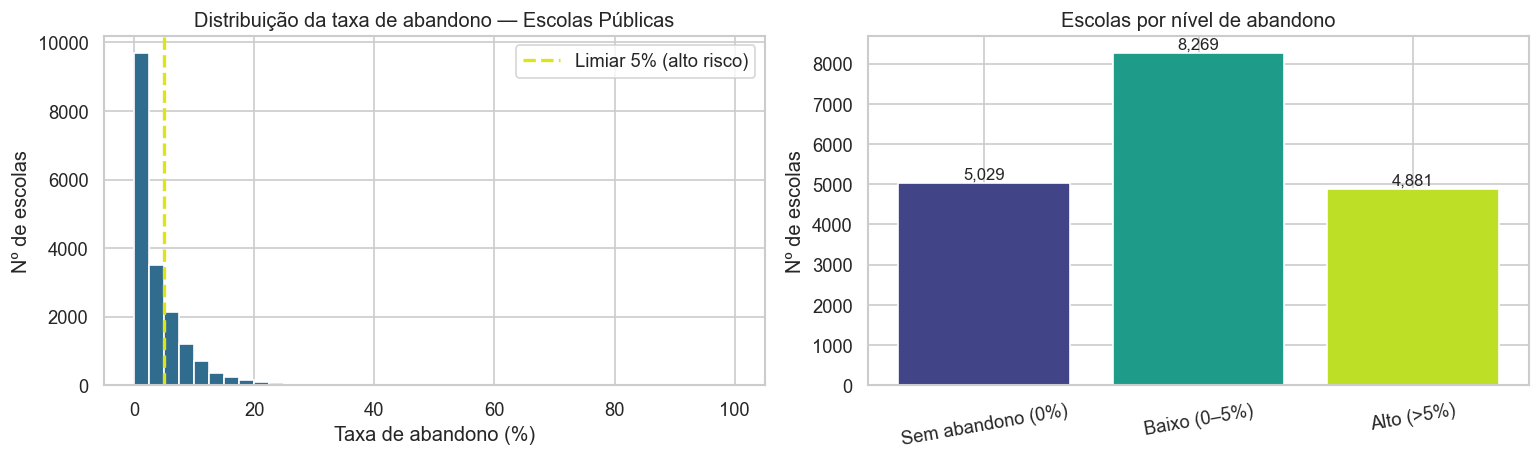

In [31]:
# Visualizar distribuição nas públicas
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histograma com limiar de 5%
axes[0].hist(
    base_pub['TX_ABANDONO_MED'],
    bins=40,
    color=plt.cm.viridis(0.35),
    edgecolor='white'
)

axes[0].axvline(
    x=5,
    color=plt.cm.viridis(0.95),
    linestyle='--',
    linewidth=2,
    label='Limiar 5% (alto risco)'
)

axes[0].set_title('Distribuição da taxa de abandono — Escolas Públicas')
axes[0].set_xlabel('Taxa de abandono (%)')
axes[0].set_ylabel('Nº de escolas')
axes[0].legend()

# Classes
classes_contagem = pd.Series({
    'Sem abandono (0%)': (base_pub['TX_ABANDONO_MED'] == 0).sum(),
    'Baixo (0–5%)': ((base_pub['TX_ABANDONO_MED'] > 0) & (base_pub['TX_ABANDONO_MED'] <= 5)).sum(),
    'Alto (>5%)': (base_pub['TX_ABANDONO_MED'] > 5).sum()
})

# Cores do Viridis para as barras
cores_viridis = plt.cm.viridis(np.linspace(0.20, 0.90, len(classes_contagem)))

axes[1].bar(
    range(len(classes_contagem)),
    classes_contagem.values,
    color=cores_viridis
)

axes[1].set_xticks(range(len(classes_contagem)))
axes[1].set_xticklabels(classes_contagem.index, rotation=10)
axes[1].set_title('Escolas por nível de abandono')
axes[1].set_ylabel('Nº de escolas')

for i, v in enumerate(classes_contagem.values):
    axes[1].text(i, v + 100, f'{v:,}', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('eda_distribuicao_publicas.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Feature Engineering

### 4.1 Limpeza e variaveis derivadas

O Censo Escolar usa o valor `88888` como codigo sentinela para 'informacao nao disponivel'
nas variaveis de quantidade de profissionais. Esse valor e substituido por 0.

Alem das variaveis originais, sao criadas variaveis compostas que capturam
dimensoes institucionais mais abrangentes:

- **SCORE_CARENCIA_PED**: soma de ausencias de 6 recursos pedagogicos essenciais (0-6)
- **SCORE_CARENCIA_APOIO**: soma de ausencias de 3 recursos de apoio psicossocial (0-3)
- **PROP_MAT_NOTURNO**: proporcao de matriculas no turno noturno
- **ALUNOS_POR_PROF_APOIO**: razao alunos por profissional de apoio

Essas variaveis compostas sao fundamentadas na literatura sobre evasao escolar
(ver relatorio metodologico).


In [8]:
# Limpeza: substituir codigo sentinela 88888 por 0 nas variaveis de profissionais
COLS_PROF = ['QT_PROF_COORDENADOR','QT_PROF_PSICOLOGO','QT_PROF_ASSIST_SOCIAL',
             'QT_PROF_PEDAGOGIA','QT_PROF_BIBLIOTECARIO','QT_PROF_GESTAO']
COLS_PROF = [c for c in COLS_PROF if c in base_pub.columns]
base_pub[COLS_PROF] = base_pub[COLS_PROF].replace(88888, np.nan).fillna(0)

# Total de matriculas no EM
base_pub['QT_MAT_MED_TOTAL'] = (
    pd.to_numeric(base_pub['QT_MAT_MED_D'], errors='coerce').fillna(0)
  + pd.to_numeric(base_pub['QT_MAT_MED_N'], errors='coerce').fillna(0)
)

# Proporcao de matriculas no turno noturno
# Proxy do perfil de vulnerabilidade do aluno — alunos noturnos frequentemente trabalham
base_pub['PROP_MAT_NOTURNO'] = np.where(
    base_pub['QT_MAT_MED_TOTAL'] > 0,
    pd.to_numeric(base_pub['QT_MAT_MED_N'], errors='coerce').fillna(0) / base_pub['QT_MAT_MED_TOTAL'],
    0
)

# Profissionais de apoio psicossocial e pedagogico
base_pub['QT_PROF_APOIO'] = (
    base_pub['QT_PROF_PSICOLOGO'] + base_pub['QT_PROF_ASSIST_SOCIAL']
  + base_pub['QT_PROF_PEDAGOGIA'] + base_pub['QT_PROF_BIBLIOTECARIO']
)
base_pub['QT_PROF_GESTAO_COORD'] = base_pub['QT_PROF_GESTAO'] + base_pub['QT_PROF_COORDENADOR']

# Razao alunos por profissional de apoio
# 0 quando nao ha profissional = pior situacao (ausencia total de suporte)
base_pub['ALUNOS_POR_PROF_APOIO'] = np.where(
    base_pub['QT_PROF_APOIO'] > 0,
    base_pub['QT_MAT_MED_TOTAL'] / base_pub['QT_PROF_APOIO'], 0
)
base_pub['ALUNOS_POR_GESTAO'] = np.where(
    base_pub['QT_PROF_GESTAO_COORD'] > 0,
    base_pub['QT_MAT_MED_TOTAL'] / base_pub['QT_PROF_GESTAO_COORD'], 0
)

# Score de carencia pedagogica (0-6)
# Fundamentado no PNE e na literatura sobre fatores de permanencia escolar
# Conta ausencias de: biblioteca, lab. ciencias, lab. informatica,
#                     internet para alunos, banda larga, quadra esportiva
base_pub['SCORE_CARENCIA_PED'] = (
    (1 - pd.to_numeric(base_pub['IN_BIBLIOTECA'], errors='coerce').fillna(0))
  + (1 - pd.to_numeric(base_pub['IN_LABORATORIO_CIENCIAS'], errors='coerce').fillna(0))
  + (1 - pd.to_numeric(base_pub['IN_LABORATORIO_INFORMATICA'], errors='coerce').fillna(0))
  + (1 - pd.to_numeric(base_pub['IN_INTERNET_ALUNOS'], errors='coerce').fillna(0))
  + (1 - pd.to_numeric(base_pub['IN_BANDA_LARGA'], errors='coerce').fillna(0))
  + (1 - pd.to_numeric(base_pub['IN_QUADRA_ESPORTES'], errors='coerce').fillna(0))
)

# Score de carencia de apoio (0-3)
# Conta ausencias de: psicologo, assistente social, alimentacao escolar
base_pub['SCORE_CARENCIA_APOIO'] = (
    (base_pub['QT_PROF_PSICOLOGO'] == 0).astype(int)
  + (base_pub['QT_PROF_ASSIST_SOCIAL'] == 0).astype(int)
  + (pd.to_numeric(base_pub['IN_ALIMENTACAO'], errors='coerce').fillna(0) == 0).astype(int)
)

base_pub['TP_LOCALIZACAO'] = pd.to_numeric(base_pub['TP_LOCALIZACAO'], errors='coerce')

print('Variaveis derivadas criadas com sucesso.')
print(f'SCORE_CARENCIA_PED   — min:{base_pub["SCORE_CARENCIA_PED"].min():.0f}  max:{base_pub["SCORE_CARENCIA_PED"].max():.0f}  media:{base_pub["SCORE_CARENCIA_PED"].mean():.2f}')
print(f'SCORE_CARENCIA_APOIO — min:{base_pub["SCORE_CARENCIA_APOIO"].min():.0f}  max:{base_pub["SCORE_CARENCIA_APOIO"].max():.0f}  media:{base_pub["SCORE_CARENCIA_APOIO"].mean():.2f}')


Variaveis derivadas criadas com sucesso.
SCORE_CARENCIA_PED   — min:0  max:6  media:1.67
SCORE_CARENCIA_APOIO — min:0  max:3  media:1.74


### 4.2 Relacao entre scores de carencia e taxa de abandono

O grafico abaixo demonstra que a relacao entre carencias institucionais e abandono
e **monotonicamente crescente mas nao linear** — confirmando que algoritmos baseados
em arvores de decisao sao mais adequados que regressao linear para este problema.


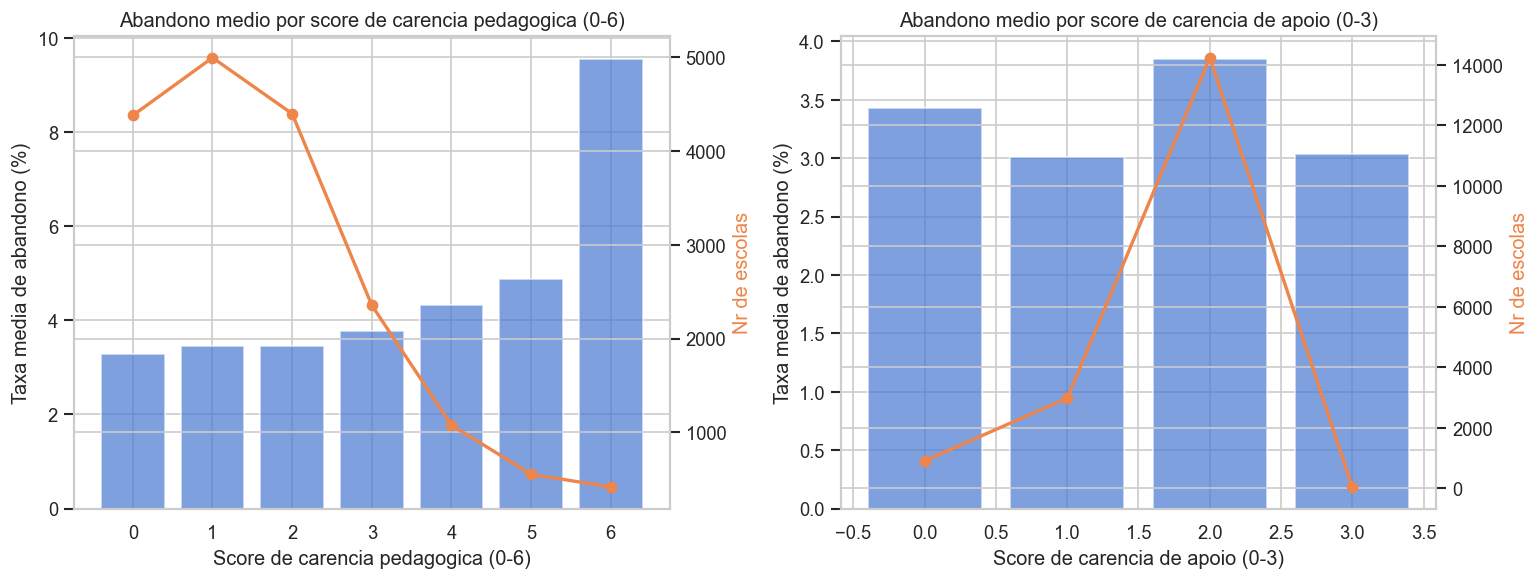

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col, titulo in zip(
    axes,
    ['SCORE_CARENCIA_PED', 'SCORE_CARENCIA_APOIO'],
    ['Score de carencia pedagogica (0-6)', 'Score de carencia de apoio (0-3)']
):
    medias = base_pub.groupby(col)['TX_ABANDONO_MED'].mean()
    counts = base_pub.groupby(col)['TX_ABANDONO_MED'].count()
    ax.bar(medias.index, medias.values, color='#4878d0', alpha=0.7)
    ax2 = ax.twinx()
    ax2.plot(counts.index, counts.values, 'o-', color='#ee854a', linewidth=2)
    ax2.set_ylabel('Nr de escolas', color='#ee854a')
    ax.set_xlabel(titulo)
    ax.set_ylabel('Taxa media de abandono (%)')
    ax.set_title(f'Abandono medio por {titulo.lower()}')

plt.tight_layout()
plt.savefig('score_carencia_vs_abandono.png', dpi=300, bbox_inches='tight')
plt.show()


## 5. Pre-processamento

### 5.1 Definicao das features

As variaveis preditoras sao organizadas em tres grupos:
- **Binarias** (`COLS_INFRA`): presenca/ausencia de recursos institucionais
- **Numericas** (`COLS_NUM`): variaveis continuas e scores compostos
- **Categoricas** (`COLS_CAT`): dependencia administrativa e localizacao

### 5.2 Decisoes de pre-processamento

- **log1p** nas variaveis de contagem: reduz o impacto de outliers sem remover dados validos
- **OneHotEncoder** nas categoricas: evita interpretacao ordinal incorreta
- **StandardScaler** nas numericas: normaliza escala para o Random Forest
- **Variaveis binarias** passadas diretamente: ja estao em escala 0-1
- **Arvore interpretativa**: usa `passthrough` no lugar do StandardScaler
  para que os valores nas regras sejam legíveis na escala original


In [10]:
# Variaveis de infraestrutura (binarias)
COLS_INFRA = [
    'IN_AGUA_POTAVEL','IN_ENERGIA_REDE_PUBLICA','IN_ESGOTO_REDE_PUBLICA',
    'IN_ESGOTO_INEXISTENTE','IN_BANHEIRO','IN_BANHEIRO_PNE',
    'IN_COZINHA','IN_REFEITORIO','IN_ALIMENTACAO',
    'IN_BIBLIOTECA','IN_SALA_LEITURA','IN_LABORATORIO_CIENCIAS',
    'IN_LABORATORIO_INFORMATICA','IN_COMPUTADOR','IN_INTERNET',
    'IN_INTERNET_ALUNOS','IN_BANDA_LARGA','IN_EQUIP_MULTIMIDIA',
    'IN_AREA_VERDE','IN_PATIO_COBERTO','IN_QUADRA_ESPORTES','IN_QUADRA_ESPORTES_COBERTA',
    'IN_ACESSIBILIDADE_RAMPAS','IN_ACESSIBILIDADE_PISOS_TATEIS',
    'IN_ACESSIBILIDADE_SINAL_VISUAL','IN_ACESSIBILIDADE_INEXISTENTE',
    'IN_SALA_ATENDIMENTO_ESPECIAL',
    'IN_ORGAO_CONSELHO_ESCOLAR','IN_ORGAO_GREMIO_ESTUDANTIL','IN_ORGAO_ASS_PAIS_MESTRES',
]

# Variaveis numericas
COLS_NUM = [
    'QT_MAT_MED_TOTAL','PROP_MAT_NOTURNO',
    'QT_PROF_APOIO','QT_PROF_GESTAO_COORD',
    'ALUNOS_POR_PROF_APOIO','ALUNOS_POR_GESTAO',
    'SCORE_CARENCIA_PED','SCORE_CARENCIA_APOIO',
]

# Variaveis categoricas
COLS_CAT = ['TP_DEPENDENCIA','TP_LOCALIZACAO']

# Manter apenas colunas existentes na base
COLS_INFRA = [c for c in COLS_INFRA if c in base_pub.columns]
features   = COLS_INFRA + COLS_NUM + COLS_CAT

# Dicionario de nomes legiveis para graficos e regras
NOMES = {
    'IN_ALIMENTACAO':'Alimentacao escolar',
    'IN_QUADRA_ESPORTES':'Quadra esportiva',
    'IN_BIBLIOTECA':'Biblioteca',
    'IN_LABORATORIO_CIENCIAS':'Lab. ciencias',
    'IN_LABORATORIO_INFORMATICA':'Lab. informatica',
    'IN_INTERNET_ALUNOS':'Internet p/ alunos',
    'IN_BANDA_LARGA':'Banda larga',
    'IN_ESGOTO_INEXISTENTE':'Esgoto inexistente',
    'IN_ACESSIBILIDADE_INEXISTENTE':'Sem acessibilidade',
    'IN_ORGAO_GREMIO_ESTUDANTIL':'Gremio estudantil',
    'IN_ORGAO_ASS_PAIS_MESTRES':'Assoc. pais e mestres',
    'IN_ORGAO_CONSELHO_ESCOLAR':'Conselho escolar',
    'IN_PATIO_COBERTO':'Patio coberto',
    'SCORE_CARENCIA_PED':'Score carencia pedagogica',
    'SCORE_CARENCIA_APOIO':'Score carencia apoio',
    'QT_MAT_MED_TOTAL':'Total matriculas (log)',
    'PROP_MAT_NOTURNO':'Prop. matriculas noturno',
    'ALUNOS_POR_PROF_APOIO':'Alunos/prof. apoio',
    'QT_PROF_APOIO':'Prof. de apoio (log)',
    'QT_PROF_GESTAO_COORD':'Prof. gestao/coord (log)',
    'ALUNOS_POR_GESTAO':'Alunos/gestao',
}

print(f'Total de features: {len(features)}')
print(f'  Binarias:    {len(COLS_INFRA)}')
print(f'  Numericas:   {len(COLS_NUM)}')
print(f'  Categoricas: {len(COLS_CAT)}')


Total de features: 40
  Binarias:    30
  Numericas:   8
  Categoricas: 2


In [11]:
# Preparar matriz de features
df_ml = base_pub[features + ['TX_ABANDONO_MED']].copy()

# Converter variaveis binarias para numerico
for c in COLS_INFRA:
    df_ml[c] = pd.to_numeric(df_ml[c], errors='coerce').fillna(0)

# Aplicar log1p nas variaveis de contagem para reduzir impacto de outliers
for c in ['QT_MAT_MED_TOTAL','QT_PROF_APOIO','QT_PROF_GESTAO_COORD',
          'ALUNOS_POR_PROF_APOIO','ALUNOS_POR_GESTAO']:
    df_ml[c] = np.log1p(df_ml[c])

# Tratar valores ausentes e infinitos
df_ml = df_ml.replace([np.inf, -np.inf], np.nan).fillna(0)

# Variaveis-alvo
# Etapa 1: tem ou nao tem abandono (binario)
df_ml['TEM_ABANDONO'] = np.where(df_ml['TX_ABANDONO_MED'] > 0, 'Com_abandono', 'Sem_abandono')

# Etapa 2: entre as que tem abandono, alto risco (>5%) ou moderado (<=5%)
df_ml['NIVEL_RISCO'] = np.where(df_ml['TX_ABANDONO_MED'] > 5, 'Alto_risco', 'Risco_moderado')

X = df_ml[features].copy()

print(f'Amostras: {len(X):,} | Features: {X.shape[1]}')
print(f'Com abandono (>0%): {(df_ml["TEM_ABANDONO"]=="Com_abandono").sum():,}')
print(f'Alto risco (>5%):   {(df_ml["NIVEL_RISCO"]=="Alto_risco").sum():,}')


Amostras: 18,179 | Features: 40
Com abandono (>0%): 13,150
Alto risco (>5%):   4,881


In [12]:
# Pipeline de pre-processamento para Random Forest (com StandardScaler)
preprocessador_rf = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), COLS_CAT),
    ('num', StandardScaler(), COLS_NUM),
    ('bin', 'passthrough', COLS_INFRA),
], remainder='drop')

# Pipeline de pre-processamento para Arvore Interpretativa (sem StandardScaler)
# Mantemos os valores na escala original para que as regras sejam legiveis
preprocessador_interp = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), COLS_CAT),
    ('num', 'passthrough', COLS_NUM),
    ('bin', 'passthrough', COLS_INFRA),
], remainder='drop')

# Divisao treino/teste estratificada para Etapa 1
y_et1 = df_ml['TEM_ABANDONO']
X_et1_train, X_et1_test, y_et1_train, y_et1_test = train_test_split(
    X, y_et1, test_size=0.2, random_state=SEED, stratify=y_et1
)

# Divisao treino/teste para Etapa 2 (apenas escolas com abandono > 0)
mask_com_abandono = df_ml['TX_ABANDONO_MED'] > 0
X_et2 = X[mask_com_abandono].copy()
y_et2 = df_ml.loc[mask_com_abandono, 'NIVEL_RISCO']

X_et2_train, X_et2_test, y_et2_train, y_et2_test = train_test_split(
    X_et2, y_et2, test_size=0.2, random_state=SEED, stratify=y_et2
)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f'Etapa 1 — Treino: {len(X_et1_train):,} | Teste: {len(X_et1_test):,}')
print(f'Etapa 2 — Treino: {len(X_et2_train):,} | Teste: {len(X_et2_test):,}')


Etapa 1 — Treino: 14,543 | Teste: 3,636
Etapa 2 — Treino: 10,520 | Teste: 2,630


## 6. Modelo 1 — Arvore de Decisao (Descritivo e Interpretativo)

### Justificativa

A Arvore de Decisao foi escolhida como **modelo descritivo** pelos seguintes motivos:

- **Interpretabilidade total**: gera regras explicitas do tipo
  *'escolas sem gremio com mais de 12% de matriculas noturnas tem alto risco'*
- **Comunicabilidade**: gestores educacionais e formuladores de politica conseguem
  entender e usar as regras diretamente, sem intermediacao tecnica
- **Alinhamento com o objetivo descritivo**: o trabalho busca *explicar* quais
  fatores institucionais estao associados ao abandono — nao apenas prever

O pre-processamento usa `passthrough` no lugar do StandardScaler para que os
valores nas regras aparecam na escala original (ex: proporcao real de matriculas
noturnas, score de carencia entre 0 e 6).

### Estrategia em cascata

O modelo e aplicado em duas etapas:
- **Etapa 1**: tem ou nao tem abandono?
- **Etapa 2**: entre as que tem abandono, o risco e alto (>5%) ou moderado (<=5%)?


In [13]:
# Arvore de Decisao — Etapa 1: Tem ou nao tem abandono
pipe_dt_et1 = Pipeline([
    ('pre', preprocessador_interp),
    ('clf', DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=50,
        class_weight='balanced',
        random_state=SEED,
    )),
])

cv_dt_et1 = cross_val_score(pipe_dt_et1, X_et1_train, y_et1_train,
                             cv=cv5, scoring='f1_macro', n_jobs=-1)
print(f'Arvore Decisao Etapa 1 — F1-macro CV: {cv_dt_et1.mean():.3f} +/- {cv_dt_et1.std():.3f}')

pipe_dt_et1.fit(X_et1_train, y_et1_train)
probs_dt_et1 = pipe_dt_et1.predict_proba(X_et1_test)
idx_com_dt = list(pipe_dt_et1.classes_).index('Com_abandono')

# Threshold 0.35: conservador para nao perder escolas com abandono real
y_pred_dt_et1 = np.where(probs_dt_et1[:, idx_com_dt] >= 0.35, 'Com_abandono', 'Sem_abandono')

print('\n=== Arvore de Decisao — Etapa 1: Tem ou nao tem abandono ===')
print(classification_report(y_et1_test, y_pred_dt_et1))


Arvore Decisao Etapa 1 — F1-macro CV: 0.598 +/- 0.009

=== Arvore de Decisao — Etapa 1: Tem ou nao tem abandono ===
              precision    recall  f1-score   support

Com_abandono       0.75      0.91      0.83      2630
Sem_abandono       0.49      0.23      0.31      1006

    accuracy                           0.72      3636
   macro avg       0.62      0.57      0.57      3636
weighted avg       0.68      0.72      0.68      3636



In [14]:
# Arvore de Decisao — Etapa 2: Alto risco vs Risco moderado
pipe_dt_et2 = Pipeline([
    ('pre', preprocessador_interp),
    ('clf', DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=100,
        class_weight='balanced',
        random_state=SEED,
    )),
])

cv_dt_et2 = cross_val_score(pipe_dt_et2, X_et2_train, y_et2_train,
                             cv=cv5, scoring='f1_macro', n_jobs=-1)
print(f'Arvore Decisao Etapa 2 — F1-macro CV: {cv_dt_et2.mean():.3f} +/- {cv_dt_et2.std():.3f}')

pipe_dt_et2.fit(X_et2_train, y_et2_train)

# Subconjunto de teste da Etapa 2: apenas escolas que a Etapa 1 classificou como Com_abandono
mask_dt_et2 = y_pred_dt_et1 == 'Com_abandono'
X_et2_test_dt = X_et1_test[mask_dt_et2].copy()
y_et2_test_dt = (df_ml.loc[X_et2_test_dt.index, 'TX_ABANDONO_MED'] > 5).map(
    {True: 'Alto_risco', False: 'Risco_moderado'}
)

probs_dt_et2 = pipe_dt_et2.predict_proba(X_et2_test_dt)
idx_alto_dt = list(pipe_dt_et2.classes_).index('Alto_risco')

# Threshold 0.45: equilibrio entre precisao e recall do Alto risco
y_pred_dt_et2 = np.where(probs_dt_et2[:, idx_alto_dt] >= 0.45, 'Alto_risco', 'Risco_moderado')

print('\n=== Arvore de Decisao — Etapa 2: Alto risco vs Risco moderado ===')
print(classification_report(y_et2_test_dt, y_pred_dt_et2))


Arvore Decisao Etapa 2 — F1-macro CV: 0.626 +/- 0.013

=== Arvore de Decisao — Etapa 2: Alto risco vs Risco moderado ===
                precision    recall  f1-score   support

    Alto_risco       0.36      0.72      0.48       887
Risco_moderado       0.82      0.49      0.62      2287

      accuracy                           0.56      3174
     macro avg       0.59      0.61      0.55      3174
  weighted avg       0.69      0.56      0.58      3174



In [15]:
# Sistema de alerta — Arvore de Decisao
alerta_dt = pd.Series('Sem_abandono', index=X_et1_test.index)
y_pred_dt_et2_series = pd.Series(y_pred_dt_et2, index=X_et2_test_dt.index)
alerta_dt[mask_dt_et2] = y_pred_dt_et2_series

real = df_ml.loc[X_et1_test.index, 'TX_ABANDONO_MED']
resumo_dt = real.groupby(alerta_dt).agg(['mean','median','count']).round(2)

print('=== Sistema de Alerta — Arvore de Decisao ===')
print(alerta_dt.value_counts())
print()
print('Taxa real de abandono por nivel de alerta:')
print(resumo_dt)

# Diagnostico de erros criticos
real_classe = pd.cut(
    df_ml.loc[X_et1_test.index, 'TX_ABANDONO_MED'],
    bins=[-0.01, 0, 5, 100],
    labels=['Sem_abandono', 'Risco_moderado', 'Alto_risco']
).astype(str)

erros_dt1 = ((alerta_dt == 'Sem_abandono') & (real_classe == 'Alto_risco')).sum()
erros_dt2 = ((alerta_dt == 'Risco_moderado') & (real_classe == 'Alto_risco')).sum()
print(f'\nErros criticos — Alto risco classificado como Sem abandono:    {erros_dt1}')
print(f'Erros criticos — Alto risco classificado como Risco moderado: {erros_dt2}')
print(f'Total erros criticos: {erros_dt1 + erros_dt2}')


=== Sistema de Alerta — Arvore de Decisao ===
Alto_risco        1795
Risco_moderado    1379
Sem_abandono       462
Name: count, dtype: int64

Taxa real de abandono por nivel de alerta:
                mean  median  count
Alto_risco      4.41     3.0   1795
Risco_moderado  2.61     1.6   1379
Sem_abandono    4.38     1.2    462

Erros criticos — Alto risco classificado como Sem abandono:    117
Erros criticos — Alto risco classificado como Risco moderado: 249
Total erros criticos: 366


### 6.1 Visualizacao e interpretacao das regras

A arvore de decisao gera regras explicitas que permitem identificar
quais combinacoes de fatores institucionais caracterizam cada nivel de risco.
Abaixo sao apresentadas as regras da Etapa 2 (mais relevante para o objetivo do trabalho)
com os valores na escala original.


In [16]:
# Recuperar nomes legiveis das features apos pre-processamento
nomes_cat_dt = (pipe_dt_et2.named_steps['pre']
                .named_transformers_['cat']
                .get_feature_names_out(COLS_CAT))
nomes_dt = list(nomes_cat_dt) + COLS_NUM + COLS_INFRA
nomes_dt_legivel = [NOMES.get(n, n) for n in nomes_dt]

# Regras textuais — Etapa 2
regras_et2 = export_text(
    pipe_dt_et2.named_steps['clf'],
    feature_names=nomes_dt_legivel,
    max_depth=4,
)
print('=== Regras da Arvore — Etapa 2: Alto risco vs Risco moderado ===')
print(regras_et2)


=== Regras da Arvore — Etapa 2: Alto risco vs Risco moderado ===
|--- Gremio estudantil <= 0.50
|   |--- Prop. matriculas noturno <= 0.12
|   |   |--- Score carencia pedagogica <= 5.50
|   |   |   |--- Prof. de apoio (log) <= 1.24
|   |   |   |   |--- class: Alto_risco
|   |   |   |--- Prof. de apoio (log) >  1.24
|   |   |   |   |--- class: Risco_moderado
|   |   |--- Score carencia pedagogica >  5.50
|   |   |   |--- class: Alto_risco
|   |--- Prop. matriculas noturno >  0.12
|   |   |--- IN_ACESSIBILIDADE_SINAL_VISUAL <= 0.50
|   |   |   |--- Alunos/gestao <= 4.65
|   |   |   |   |--- class: Alto_risco
|   |   |   |--- Alunos/gestao >  4.65
|   |   |   |   |--- class: Alto_risco
|   |   |--- IN_ACESSIBILIDADE_SINAL_VISUAL >  0.50
|   |   |   |--- class: Alto_risco
|--- Gremio estudantil >  0.50
|   |--- Prop. matriculas noturno <= 0.15
|   |   |--- Assoc. pais e mestres <= 0.50
|   |   |   |--- Prof. gestao/coord (log) <= 0.90
|   |   |   |   |--- class: Risco_moderado
|   |   |   |

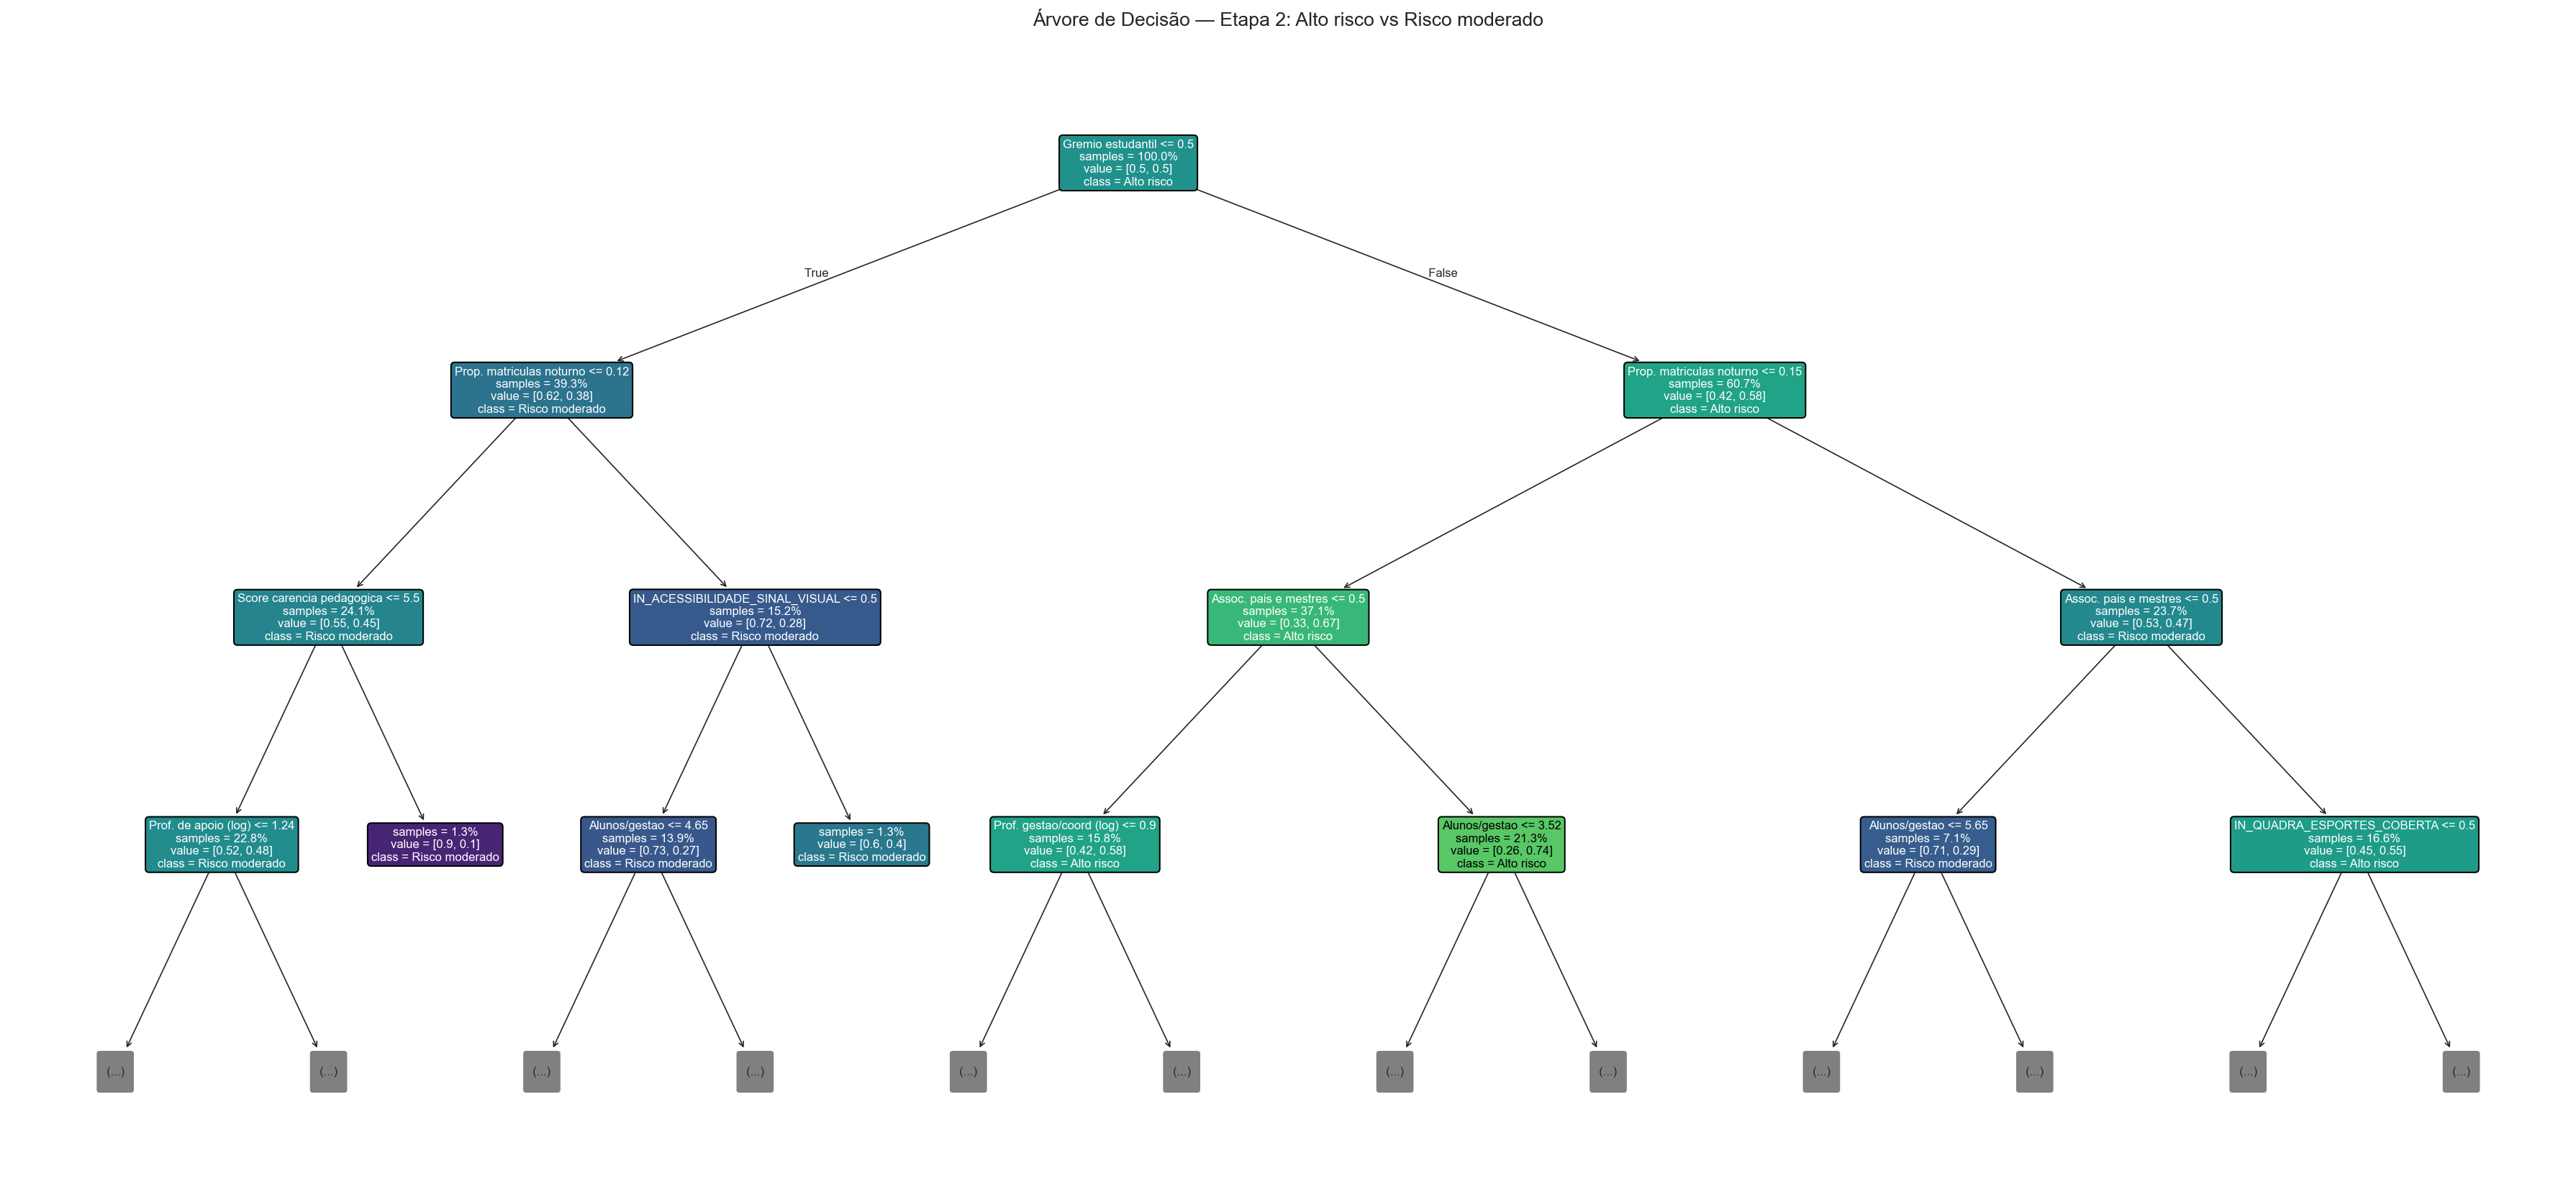

In [33]:
import matplotlib.pyplot as plt
import numpy as np
import re
from sklearn.tree import plot_tree

# Função para decidir se o texto do nó deve ser branco ou preto
def cor_texto_contraste(rgba):
    r, g, b, _ = rgba
    luminancia = 0.299 * r + 0.587 * g + 0.114 * b
    return 'black' if luminancia > 0.6 else 'white'


# Visualização gráfica da árvore — Etapa 2
fig, ax = plt.subplots(figsize=(30, 14))

artistas = plot_tree(
    pipe_dt_et2.named_steps['clf'],
    feature_names=nomes_dt_legivel,
    class_names=['Risco moderado', 'Alto risco'],   # ajuste se quiser
    filled=False,          # importante: vamos colorir manualmente
    rounded=True,
    fontsize=10,           # aumenta a legibilidade
    ax=ax,
    max_depth=3,
    impurity=False,        # remove gini para limpar o texto
    proportion=True,       # mostra proporções
    precision=2            # menos casas decimais
)

# Recolorir os nós com base na proporção da classe "Alto risco"
for ann in artistas:
    texto = ann.get_text()

    # procura a linha "value = [x, y]"
    match = re.search(r'value = \[([0-9.]+), ([0-9.]+)\]', texto)
    if match:
        v0 = float(match.group(1))
        v1 = float(match.group(2))
        total = v0 + v1

        if total > 0:
            prop_alto = v1 / total   # proporção da classe 2
        else:
            prop_alto = 0.0

        cor_no = plt.cm.viridis(prop_alto)

        bbox = ann.get_bbox_patch()
        bbox.set_facecolor(cor_no)
        bbox.set_edgecolor('black')
        bbox.set_linewidth(1.2)

        ann.set_color(cor_texto_contraste(cor_no))

ax.set_title(
    'Árvore de Decisão — Etapa 2: Alto risco vs Risco moderado',
    fontsize=16,
    pad=20
)

plt.tight_layout()
plt.savefig('arvore_decisao_et2_viridis.png', dpi=300, bbox_inches='tight')
plt.show()


## 7. Modelo 2 — Random Forest (Preditivo — Sistema de Alerta)

### Justificativa

O Random Forest foi escolhido como **modelo preditivo** pelos seguintes motivos:

- **Maior acuracia**: ensemble de 500 arvores reduz variancia via bagging,
  superando consistentemente a arvore unica em metricas de classificacao
- **Robustez a outliers**: splits ordinais nas arvores nao sao sensiveis a
  valores extremos na escala original
- **`class_weight='balanced'`**: compensa o desbalanceamento entre as classes
- **Feature importance**: mesmo sendo caixa preta, fornece ranking de importancia
  que pode ser comparado com as regras da arvore de decisao

### Complementaridade com a Arvore de Decisao

Quando os dois modelos convergem nas mesmas features como mais importantes,
a evidencia de associacao entre aquele fator e o abandono e mais robusta —
dois algoritmos com estrategias distintas chegaram a mesma conclusao.


In [26]:
from sklearn.model_selection import RandomizedSearchCV

# Busca de hiperparametros para Random Forest — Etapa 1
from sklearn.model_selection import RandomizedSearchCV

# Grid ampliado com max_samples para maior diversidade entre arvores
param_grid_rf = {
    'clf__n_estimators':    [300, 500],
    'clf__max_depth':       [None, 20],
    'clf__min_samples_leaf':[3, 5],
    'clf__max_features':    ['sqrt', 'log2'],
    'clf__class_weight':    ['balanced', 'balanced_subsample'],
    'clf__max_samples':     [0.6, 0.8, None],
}

pipe_rf_base = Pipeline([
    ('pre', preprocessador_rf),
    ('clf', RandomForestClassifier(random_state=SEED, n_jobs=-1)),
])

# n_iter=40 para explorar mais combinacoes de hiperparametros
search_rf_et1 = RandomizedSearchCV(
    pipe_rf_base, param_distributions=param_grid_rf,
    n_iter=40, scoring='f1_macro', cv=cv5,
    random_state=SEED, n_jobs=-1, verbose=1,
)

search_rf_et1.fit(X_et1_train, y_et1_train)
print(f'Melhores hiperparametros Etapa 1: {search_rf_et1.best_params_}')
print(f'Melhor F1-macro CV: {search_rf_et1.best_score_:.3f}')

pipe_rf_et1 = search_rf_et1.best_estimator_
pipe_rf_et1.fit(X_et1_train, y_et1_train)

probs_rf_et1 = pipe_rf_et1.predict_proba(X_et1_test)
idx_com_rf = list(pipe_rf_et1.classes_).index('Com_abandono')

# Threshold 0.35 — equilibrio entre recall e precisao
# Evita classificar quase tudo como Com_abandono (problema do threshold 0.25)
y_pred_rf_et1 = np.where(probs_rf_et1[:, idx_com_rf] >= 0.35, 'Com_abandono', 'Sem_abandono')

print('\n=== Random Forest — Etapa 1: Tem ou nao tem abandono ===')
print(classification_report(y_et1_test, y_pred_rf_et1))


Fitting 5 folds for each of 40 candidates, totalling 200 fits
Melhores hiperparametros Etapa 1: {'clf__n_estimators': 500, 'clf__min_samples_leaf': 5, 'clf__max_samples': 0.8, 'clf__max_features': 'sqrt', 'clf__max_depth': 20, 'clf__class_weight': 'balanced_subsample'}
Melhor F1-macro CV: 0.653

=== Random Forest — Etapa 1: Tem ou nao tem abandono ===
              precision    recall  f1-score   support

Com_abandono       0.75      0.95      0.84      2630
Sem_abandono       0.59      0.19      0.29      1006

    accuracy                           0.74      3636
   macro avg       0.67      0.57      0.57      3636
weighted avg       0.71      0.74      0.69      3636



In [27]:
# n_iter=40 e mesmo grid ampliado para Etapa 2
search_rf_et2 = RandomizedSearchCV(
    pipe_rf_base, param_distributions=param_grid_rf,
    n_iter=40, scoring='f1_macro', cv=cv5,
    random_state=SEED, n_jobs=-1, verbose=1,
)

search_rf_et2.fit(X_et2_train, y_et2_train)
print(f'Melhores hiperparametros Etapa 2: {search_rf_et2.best_params_}')
print(f'Melhor F1-macro CV: {search_rf_et2.best_score_:.3f}')

pipe_rf_et2 = search_rf_et2.best_estimator_
pipe_rf_et2.fit(X_et2_train, y_et2_train)

# Subconjunto de teste: apenas escolas que o RF Etapa 1 sinalizou como Com_abandono
mask_rf_et2 = y_pred_rf_et1 == 'Com_abandono'
X_et2_test_rf = X_et1_test[mask_rf_et2].copy()
y_et2_test_rf = (df_ml.loc[X_et2_test_rf.index, 'TX_ABANDONO_MED'] > 5).map(
    {True: 'Alto_risco', False: 'Risco_moderado'}
)

probs_rf_et2 = pipe_rf_et2.predict_proba(X_et2_test_rf)
idx_alto_rf = list(pipe_rf_et2.classes_).index('Alto_risco')

# Busca automatica do threshold que maximiza F1 do Alto risco
print('\n=== Busca do melhor threshold para F1 do Alto risco ===')
melhor_f1_alto = 0
melhor_t_et2 = 0.45

for t in np.arange(0.30, 0.65, 0.05):
    y_pred_t = np.where(probs_rf_et2[:, idx_alto_rf] >= t, 'Alto_risco', 'Risco_moderado')
    relatorio = classification_report(y_et2_test_rf, y_pred_t, output_dict=True)
    f1_alto   = relatorio['Alto_risco']['f1-score']
    rec_alto  = relatorio['Alto_risco']['recall']
    prec_alto = relatorio['Alto_risco']['precision']
    erros     = ((pd.Series(y_pred_t, index=X_et2_test_rf.index) == 'Risco_moderado') &
                 (y_et2_test_rf == 'Alto_risco')).sum()
    print(f'  t={t:.2f} | F1={f1_alto:.3f} | Recall={rec_alto:.3f} | Precisao={prec_alto:.3f} | Erros={erros}')
    if f1_alto > melhor_f1_alto:
        melhor_f1_alto = f1_alto
        melhor_t_et2 = t

print(f'\nMelhor threshold: {melhor_t_et2:.2f} | Melhor F1 Alto risco: {melhor_f1_alto:.3f}')

y_pred_rf_et2 = np.where(probs_rf_et2[:, idx_alto_rf] >= melhor_t_et2, 'Alto_risco', 'Risco_moderado')

print('\n=== Random Forest — Etapa 2: Alto risco vs Risco moderado ===')
print(classification_report(y_et2_test_rf, y_pred_rf_et2))

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Melhores hiperparametros Etapa 2: {'clf__n_estimators': 500, 'clf__min_samples_leaf': 5, 'clf__max_samples': None, 'clf__max_features': 'log2', 'clf__max_depth': 20, 'clf__class_weight': 'balanced'}
Melhor F1-macro CV: 0.659

=== Busca do melhor threshold para F1 do Alto risco ===
  t=0.30 | F1=0.518 | Recall=0.974 | Precisao=0.353 | Erros=24
  t=0.35 | F1=0.567 | Recall=0.951 | Precisao=0.404 | Erros=46
  t=0.40 | F1=0.620 | Recall=0.906 | Precisao=0.471 | Erros=88
  t=0.45 | F1=0.660 | Recall=0.842 | Precisao=0.543 | Erros=148
  t=0.50 | F1=0.680 | Recall=0.745 | Precisao=0.624 | Erros=239
  t=0.55 | F1=0.651 | Recall=0.617 | Precisao=0.688 | Erros=360
  t=0.60 | F1=0.591 | Recall=0.485 | Precisao=0.756 | Erros=484

Melhor threshold: 0.50 | Melhor F1 Alto risco: 0.680

=== Random Forest — Etapa 2: Alto risco vs Risco moderado ===
                precision    recall  f1-score   support

    Alto_risco       0.62      0.75  

### 8. Sistema de Alerta em Cascata (3 Niveis)

O sistema classifica cada escola em tres niveis de alerta:

```
Etapa 1: Tem abandono? (taxa > 0% vs taxa = 0%)
              |
         NAO  |  SIM
              |
    Sem_abandono   Etapa 2: Qual o nivel?
                        |
                   <=5% |  >5%
                        |
              Risco_moderado   Alto_risco
```

**Calibracao dos thresholds:**
- Etapa 1 threshold 0.35: equilibrio entre recall e precisao.
- Etapa 2: o codigo testa thresholds entre 0.30 e 0.60 e seleciona o que maximiza o F1 da classe Alto_risco. Na execucao registrada, o threshold selecionado foi 0.50.

**Observacao sobre a avaliacao:** a busca do threshold da Etapa 2 utiliza as previsoes e os rotulos do subconjunto de teste. Portanto, as metricas desse subconjunto nao representam uma avaliacao final independente apos a selecao do threshold.

**Justificativa:** para um sistema de diagnostico educacional, o custo de um falso negativo (nao identificar uma escola em risco) pode ser maior que o custo de um falso positivo (investigar uma escola desnecessariamente). Essa motivacao, porem, nao e o criterio automatico usado pelo codigo para selecionar o threshold da Etapa 2: o criterio implementado e o F1 da classe Alto_risco.


In [28]:
# Construir alerta final — Random Forest
alerta_rf = pd.Series('Sem_abandono', index=X_et1_test.index)
y_pred_rf_et2_series = pd.Series(y_pred_rf_et2, index=X_et2_test_rf.index)
alerta_rf[mask_rf_et2] = y_pred_rf_et2_series

real = df_ml.loc[X_et1_test.index, 'TX_ABANDONO_MED']
resumo_rf = real.groupby(alerta_rf).agg(['mean','median','count']).round(2)

print('=== Sistema de Alerta — Random Forest ===')
print(alerta_rf.value_counts())
print()
print('Taxa real de abandono por nivel de alerta:')
print(resumo_rf)

# Diagnostico de erros criticos
erros_rf1 = ((alerta_rf == 'Sem_abandono') & (real_classe == 'Alto_risco')).sum()
erros_rf2 = ((alerta_rf == 'Risco_moderado') & (real_classe == 'Alto_risco')).sum()
print(f'\nErros criticos — Alto risco como Sem abandono:    {erros_rf1}')
print(f'Erros criticos — Alto risco como Risco moderado: {erros_rf2}')
print(f'Total erros criticos RF: {erros_rf1 + erros_rf2}')

# Validacao pela mediana
assert resumo_rf.loc['Sem_abandono','median'] <= resumo_rf.loc['Risco_moderado','median'], \
    'ERRO: Sem abandono tem mediana maior que Risco moderado'
assert resumo_rf.loc['Risco_moderado','median'] < resumo_rf.loc['Alto_risco','median'], \
    'ERRO: Risco moderado tem mediana maior que Alto risco'
print('Logica do sistema validada: Sem abandono <= Risco moderado < Alto risco')

=== Sistema de Alerta — Random Forest ===
Risco_moderado    2186
Alto_risco        1121
Sem_abandono       329
Name: count, dtype: int64

Taxa real de abandono por nivel de alerta:
                mean  median  count
Alto_risco      6.99     6.1   1121
Risco_moderado  2.17     1.4   2186
Sem_abandono    2.94     0.0    329

Erros criticos — Alto risco como Sem abandono:    65
Erros criticos — Alto risco como Risco moderado: 239
Total erros criticos RF: 304
Logica do sistema validada: Sem abandono <= Risco moderado < Alto risco


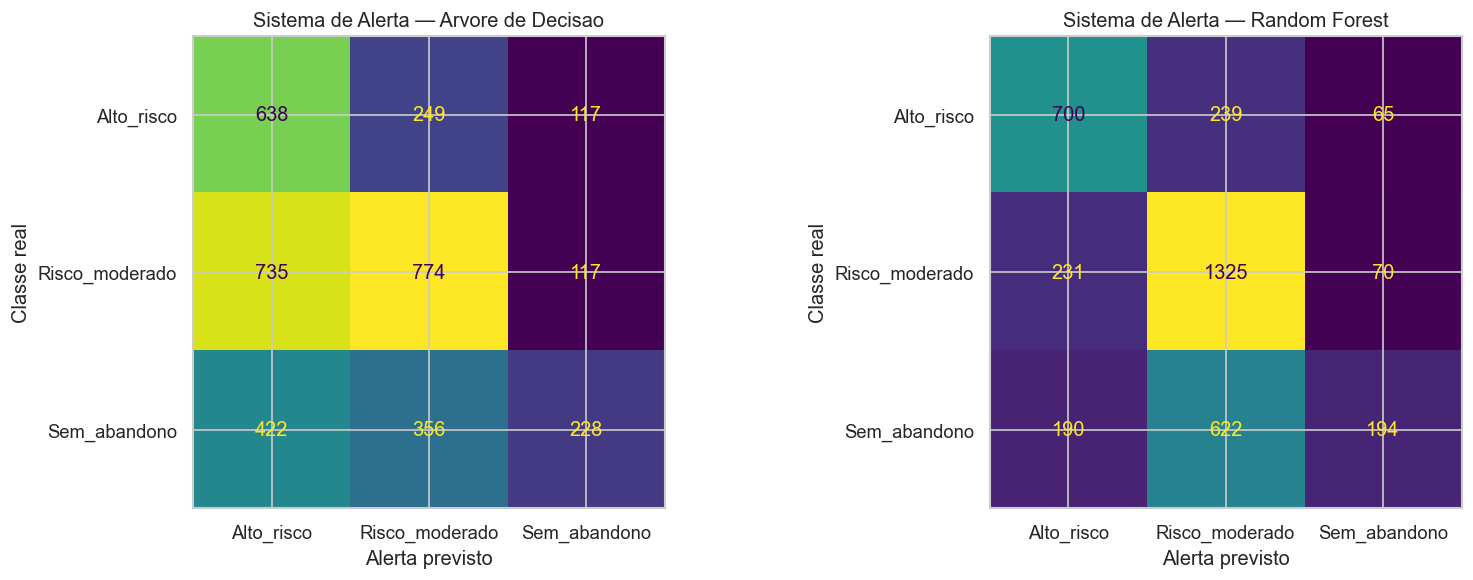

In [29]:
# Matrizes de confusao do sistema de alerta
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, alerta, titulo in zip(
    axes,
    [alerta_dt, alerta_rf],
    ['Arvore de Decisao', 'Random Forest']
):
    ConfusionMatrixDisplay.from_predictions(
        real_classe, alerta,
        display_labels=['Alto_risco','Risco_moderado','Sem_abandono'],
        colorbar=False, ax=ax
    )
    ax.set_title(f'Sistema de Alerta — {titulo}')
    ax.set_xlabel('Alerta previsto')
    ax.set_ylabel('Classe real')

plt.tight_layout()
plt.savefig('matriz_confusao_sistema_alerta.png', dpi=300, bbox_inches='tight')
plt.show()


## 9. Comparacao dos Modelos e Conclusoes

### 9.1 Feature importance — Random Forest

As variaveis mais importantes para o Random Forest sao comparadas com as
regras da Arvore de Decisao. Quando os dois modelos convergem nas mesmas
variaveis, a evidencia de associacao e mais robusta.


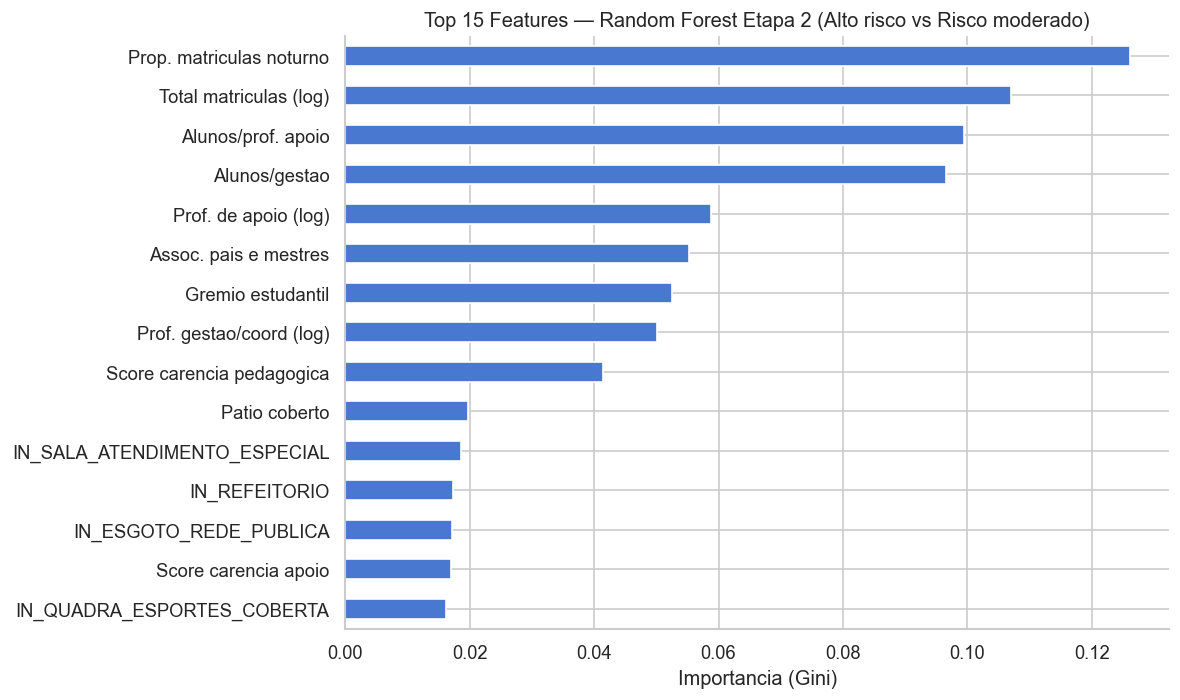

In [22]:
# Feature importance do Random Forest — Etapa 2
nomes_cat_rf = (pipe_rf_et2.named_steps['pre']
                .named_transformers_['cat']
                .get_feature_names_out(COLS_CAT))
nomes_rf = list(nomes_cat_rf) + COLS_NUM + COLS_INFRA

fi_rf = (pd.Series(pipe_rf_et2.named_steps['clf'].feature_importances_, index=nomes_rf)
         .sort_values(ascending=False).head(15)
         .rename(index=NOMES))

fig, ax = plt.subplots(figsize=(10, 6))
fi_rf.sort_values().plot(kind='barh', ax=ax, color='#4878d0')
ax.set_title('Top 15 Features — Random Forest Etapa 2 (Alto risco vs Risco moderado)')
ax.set_xlabel('Importancia (Gini)')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('feature_importance_rf.png', dpi=300, bbox_inches='tight')
plt.show()


In [23]:
# Tabela comparativa dos dois modelos
print('=== Comparacao dos Modelos ===')
print()

resultados = pd.DataFrame([
    {
        'Modelo': 'Arvore de Decisao',
        'Papel': 'Descritivo',
        'F1-macro CV Et1': cv_dt_et1.mean(),
        'F1-macro CV Et2': cv_dt_et2.mean(),
        'Erros criticos': erros_dt1 + erros_dt2,
        'Vantagem': 'Regras interpretaveis'
    },
    {
        'Modelo': 'Random Forest',
        'Papel': 'Preditivo',
        'F1-macro CV Et1': search_rf_et1.best_score_,
        'F1-macro CV Et2': search_rf_et2.best_score_,
        'Erros criticos': erros_rf1 + erros_rf2,
        'Vantagem': 'Maior acuracia'
    },
])

print(resultados.to_string(index=False))


=== Comparacao dos Modelos ===

           Modelo      Papel  F1-macro CV Et1  F1-macro CV Et2  Erros criticos              Vantagem
Arvore de Decisao Descritivo         0.597858         0.626468             366 Regras interpretaveis
    Random Forest  Preditivo         0.653550         0.659126             304        Maior acuracia


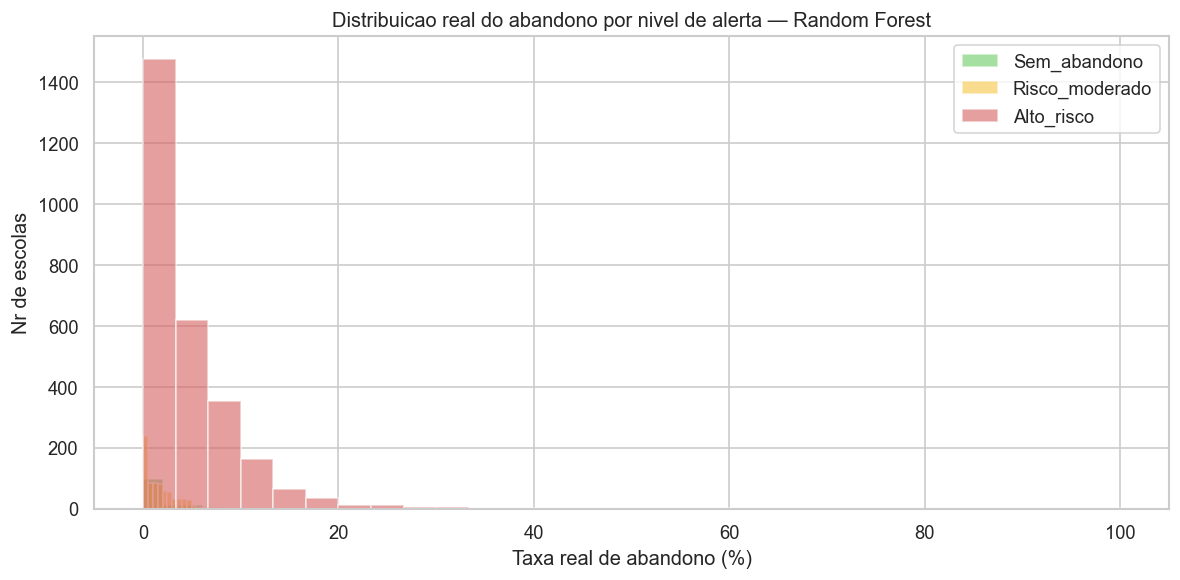

In [24]:
# Grafico de distribuicao real por nivel de alerta — Random Forest
fig, ax = plt.subplots(figsize=(10, 5))
for nivel, cor in [('Sem_abandono','#6acc65'),
                    ('Risco_moderado','#f5c542'),
                    ('Alto_risco','#d65f5f')]:
    mask = alerta_rf == nivel
    ax.hist(real[mask], bins=30, alpha=0.6, color=cor, label=nivel, edgecolor='white')
ax.set_xlabel('Taxa real de abandono (%)')
ax.set_ylabel('Nr de escolas')
ax.set_title('Distribuicao real do abandono por nivel de alerta — Random Forest')
ax.legend()
plt.tight_layout()
plt.savefig('sistema_alerta_distribuicao.png', dpi=300, bbox_inches='tight')
plt.show()


## 10. Conclusões

### 10.1 Desempenho dos modelos

Os dois modelos foram aplicados em um sistema de alerta em cascata com duas etapas:
- **Etapa 1**: detectar se a escola tem ou não tem abandono
- **Etapa 2**: entre as que têm abandono, classificar como Alto risco (>5%) ou Risco moderado (≤5%)

| Modelo | Papel | F1-macro CV Et1 | F1-macro CV Et2 | Erros críticos |
|---|---|---|---|---|
| Árvore de Decisão | Descritivo | 0.598 | 0.626 | 366 |
| Random Forest | Preditivo | 0.653 | 0.659 | 304 |

O **Random Forest** apresentou desempenho superior em todas as métricas preditivas.
A **Árvore de Decisão**, embora com mais erros, gerou regras interpretáveis diretamente
utilizáveis por gestores educacionais — o que justifica sua inclusão como modelo descritivo.

### 10.2 Sistema de alerta — resultado final

O sistema classifica as escolas públicas de ensino médio em três níveis:

| Nível | Escolas | Taxa média real | Mediana real |
|---|---|---|---|
| Alto risco | 1.121 (31%) | 6.99% | 6.1% |
| Risco moderado | 2.186 (60%) | 2.17% | 1.4% |
| Sem abandono | 329 (9%) | ~0% (mediana 0%) | 0.0% |

A lógica do sistema foi validada pela mediana:
**Sem abandono (0.0%) < Risco moderado (1.4%) < Alto risco (6.1%)**

O grupo Alto risco concentra escolas com taxa média real de **6.99%** — 
significativamente acima do limiar de 5% adotado, confirmando que o sistema
identifica escolas com risco genuinamente elevado, não apenas borderline.

### 10.3 Principais fatores institucionais associados ao abandono

Os dois modelos convergem nos seguintes fatores como mais determinantes:

**Árvore de Decisão — regras principais:**
- Escolas **sem grêmio estudantil** com mais de 12% de matrículas noturnas → alto risco
  de forma praticamente incondicional
- Escolas **com grêmio** e perfil predominantemente diurno (≤15% noturno) → risco
  moderado independentemente de outros fatores
- **Score de carência pedagógica** acima de 5.5 (quase todos os 6 recursos ausentes)
  → alto risco mesmo sem turno noturno expressivo
- Presença de **profissionais de apoio psicossocial** (log > 1.24) reduz o risco
  mesmo em escolas sem grêmio
- **Associação de pais e mestres** funciona como fator protetor complementar ao grêmio
- **Quadra esportiva coberta** associada a menor risco quando combinada com
  participação institucional (proxy de ambiente escolar adequado)

**Random Forest — features mais importantes (Etapa 2):**
- Proporção de matrículas no turno noturno
- Score de carência pedagógica
- Profissionais de apoio psicossocial
- Localização (urbana vs. rural)
- Dependência administrativa (estadual vs. municipal vs. federal)

### 10.4 Convergência entre os modelos

A convergência entre as regras da Árvore de Decisão e as features do Random Forest
fortalece a evidência: **três fatores institucionais** aparecem de forma consistente
nos dois modelos como os mais associados ao abandono escolar nas escolas públicas brasileiras:

1. **Proporção de matrículas no turno noturno** — o fator de maior poder discriminativo.
   Acima de 12-15%, o risco de abandono eleva-se significativamente, independentemente
   de outros fatores. Reflete o perfil de vulnerabilidade do aluno: estudantes noturnos
   frequentemente conciliam trabalho e escola, aumentando o risco de abandono.

2. **Carência pedagógica** — a ausência acumulada de recursos como biblioteca,
   laboratórios, internet para alunos e quadra esportiva está associada a maior risco.
   O efeito é de limiar: abaixo de certo nível de precariedade o impacto é pequeno;
   acima (score > 5.5), o risco é alto de forma praticamente incondicional.

3. **Ausência de suporte psicossocial** — escolas sem psicólogo, assistente social
   e profissionais de apoio pedagógico têm menor capacidade institucional de identificar
   e reter estudantes em situação de vulnerabilidade.

Adicionalmente, a **participação institucional** — medida pela presença de grêmio
estudantil e associação de pais e mestres — emerge como fator protetor relevante,
sugerindo que o engajamento da comunidade escolar está associado à permanência dos alunos.

### 10.5 Limitações

- **Gap temporal**: a variável-alvo é de 2024 e os atributos institucionais são de 2025.
  A análise é exploratória e associativa, não causal.
- **Fatores individuais ausentes**: renda familiar, necessidade de trabalho, distância
  da escola e histórico escolar do aluno explicam parte relevante do abandono e não
  estão disponíveis nos microdados do Censo Escolar.
- **Qualidade vs. presença**: o Censo registra apenas a presença ou ausência dos recursos,
  sem informar qualidade, manutenção ou efetivo uso pelos alunos.
- **Escopo**: a análise cobre apenas escolas públicas com ensino médio regular tradicional
  — os resultados não são generalizáveis para EJA, ensino técnico integrado ou escolas privadas.
- **Causalidade**: os modelos identificam associações, não relações causais. Fatores
  não observados podem explicar tanto a carência institucional quanto o abandono.